# Chapitre 6 - Lissage par noyaux (1) : lisseurs unidimensionnels

Ce premier notebook de cours couvre les sections 6.1, 6.2 et 6.9 du livre.
L'idée directrice du chapitre est simple : pour estimer la fonction de régression
$f(x) = \mathbb E(Y \mid X = x)$ en un point $x_0$, on ajuste un modèle **très simple**
(une constante, une droite, une parabole) en n'utilisant **que les observations proches
de $x_0$**. On recommence pour chaque point cible : la fonction estimée $\hat f$ est la
collection de tous ces ajustements locaux.

La « proximité » est quantifiée par un **noyau** $K_\lambda(x_0, x_i)$ : un poids positif,
grand quand $x_i$ est proche de $x_0$ et qui décroît (souvent jusqu'à zéro) quand on
s'éloigne. Le paramètre $\lambda$ règle la largeur du voisinage.

> **Remarque.** Ces noyaux servent ici à **localiser**. Ils ne doivent pas être confondus
> avec les « noyaux reproduisants » des méthodes à noyaux (chapitres 5.8 et 12), qui
> calculent des produits scalaires dans un espace de grande dimension.

**Plan.**
1. Des k plus proches voisins à la moyenne pondérée de Nadaraya-Watson (fig. 6.1).
2. Trois noyaux classiques (fig. 6.2) et largeur métrique ou adaptative.
3. Régression linéaire locale et correction des effets de bord (fig. 6.3).
4. Noyau équivalent et biais (fig. 6.4), polynômes locaux (fig. 6.5), variance (fig. 6.6).
5. Choix de la largeur : compromis biais-variance, degrés de liberté, validation croisée,
   comparaison avec les splines de lissage (fig. 6.7).
6. Considérations de calcul.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch06_noyaux as nk
set_style()
GREEN, YELLOW, RED = COLORS[2], COLORS[3], COLORS[7]

## 1. Des k plus proches voisins à Nadaraya-Watson

### Les données simulées du livre

On reprend l'exemple de la figure 6.1 : $N = 100$ couples $(x_i, y_i)$ avec
$$
X \sim \mathcal U[0, 1], \qquad Y = \sin(4X) + \varepsilon, \qquad
\varepsilon \sim \mathcal N(0, 1/3).
$$
La vraie fonction de régression est donc $f(x) = \sin(4x)$, que nous connaissons, ce qui
permet de juger les estimateurs.

In [2]:
rng = np.random.RandomState(0)
N = 100
x = np.sort(rng.uniform(0, 1, N))
f_true = lambda t: np.sin(4 * t)
sigma = np.sqrt(1 / 3)
y = f_true(x) + sigma * rng.normal(size=N)
grid = np.linspace(0, 1, 401)
print("x dans [%.3f, %.3f], écart-type du bruit = %.3f" % (x.min(), x.max(), sigma))

x dans [0.005, 0.988], écart-type du bruit = 0.577


### La moyenne des k plus proches voisins

Au chapitre 2, on a estimé $\mathbb E(Y \mid X = x)$ par la moyenne des réponses des
$k$ points les plus proches (éq. (6.1) du livre) :
$$
\hat f(x) = \operatorname{Ave}\big(y_i \;\big|\; x_i \in N_k(x)\big),
$$
où $N_k(x)$ est l'ensemble des $k$ indices $i$ dont les $x_i$ sont les plus proches de $x$.
On « relâche » l'espérance conditionnelle (qui conditionne sur $X = x$ exactement) en
moyennant sur un **voisinage** de $x$.

**Défaut.** Quand $x_0$ se déplace vers la droite, le voisinage reste le même jusqu'à ce
qu'un nouveau point à droite devienne plus proche que le point le plus éloigné à gauche ;
celui-ci est alors **brutalement** remplacé. Chaque point entre ou sort avec un poids
$1/k$ d'un coup : $\hat f$ est une fonction **en escalier**, discontinue.

Le remède : donner aux points des poids qui **décroissent continûment** avec la distance.

### La moyenne pondérée de Nadaraya-Watson

L'estimateur de Nadaraya-Watson (éq. (6.2) du livre) est la moyenne pondérée
$$
\hat f(x_0) = \frac{\sum_{i=1}^N K_\lambda(x_0, x_i)\, y_i}{\sum_{i=1}^N K_\lambda(x_0, x_i)},
$$
avec par exemple le noyau quadratique d'Epanechnikov (éq. (6.3)-(6.4)) :
$$
K_\lambda(x_0, x) = D\!\left(\frac{|x - x_0|}{\lambda}\right), \qquad
D(t) = \begin{cases} \tfrac34 (1 - t^2) & \text{si } |t| \le 1,\\ 0 & \text{sinon.}\end{cases}
$$
Ici $\lambda$ est le **rayon** de la fenêtre : seuls les $x_i$ à distance $< \lambda$ de
$x_0$ comptent.

> **Intuition.** C'est un barycentre des $y_i$ : les poids normalisés
> $w_i(x_0) = K_\lambda(x_0, x_i) / \sum_j K_\lambda(x_0, x_j)$ sont positifs et de somme 1.
> Quand $x_0$ bouge, un point qui entre dans la fenêtre arrive avec un poids **nul**
> (car $D(1) = 0$) qui augmente progressivement : plus de saut.

### Figure 6.1

À gauche, le lisseur des 30 plus proches voisins ; à droite, Nadaraya-Watson avec le noyau
d'Epanechnikov et $\lambda = 0{,}2$. Au point $x_0 = 0{,}45$ on montre les observations
utilisées (cercles rouges) et, en jaune, la forme des poids.

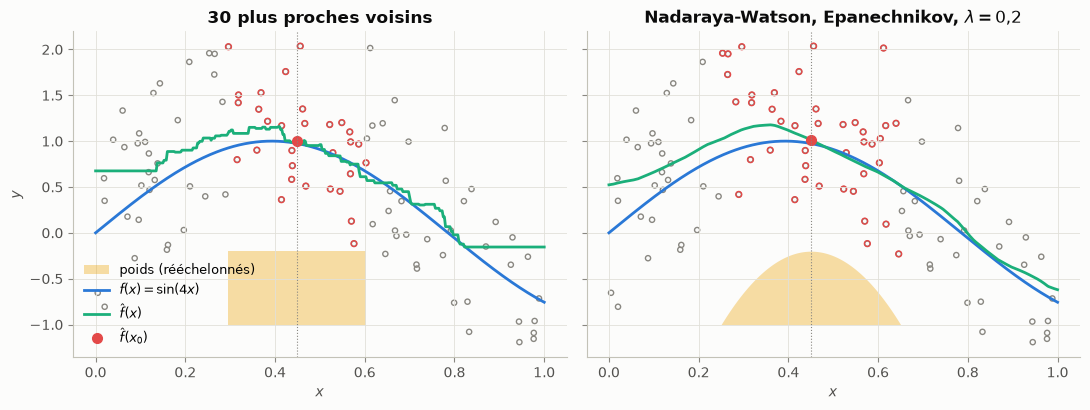

In [3]:
x0 = 0.45
fit_knn = nk.knn_mean(grid, x, y, 30)
fit_nw = nk.nadaraya_watson(grid, x, y, lam=0.2, kernel="epanechnikov")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, name in zip(axes, ["knn", "nw"]):
    if name == "knn":
        idx = np.argsort(np.abs(x - x0))[:30]
        w = np.zeros(N); w[idx] = 1.0
        fit, fx0, title = fit_knn, y[idx].mean(), "30 plus proches voisins"
        lo, hi = x[idx].min(), x[idx].max()
        ax.fill_between([lo, hi], -1.0, -1.0 + 0.8, color=YELLOW, alpha=0.35, lw=0,
                        label="poids (rééchelonnés)")
    else:
        w = nk.kernel_weights([x0], x, lam=0.2)[0]
        fx0, fit, title = np.sum(w * y) / w.sum(), fit_nw, "Nadaraya-Watson, Epanechnikov, $\\lambda=0{,}2$"
        tt = np.linspace(x0 - 0.2, x0 + 0.2, 100)
        ax.fill_between(tt, -1.0, -1.0 + 0.8 * nk.epanechnikov((tt - x0) / 0.2) / 0.75,
                        color=YELLOW, alpha=0.35, lw=0, label="poids (rééchelonnés)")
    ax.scatter(x, y, s=14, facecolors="none", edgecolors=GRAY)
    ax.scatter(x[w > 0], y[w > 0], s=18, facecolors="none", edgecolors=RED)
    ax.plot(grid, f_true(grid), color=BLUE, label="$f(x)=\\sin(4x)$")
    ax.plot(grid, fit, color=GREEN, label="$\\hat f(x)$")
    ax.plot([x0], [fx0], "o", color=RED, ms=7, label="$\\hat f(x_0)$")
    ax.axvline(x0, color=GRAY, lw=0.8, ls=":")
    ax.set_title(title); ax.set_xlabel("$x$")
axes[0].set_ylabel("$y$"); axes[0].legend(loc="lower left")
plt.tight_layout(); plt.show()

La courbe verte de gauche est cahoteuse (constante par morceaux), celle de droite est
continue et beaucoup plus lisse. L'exercice 6.1 étudie précisément la régularité de
$\hat f$ selon le noyau.

## 2. Noyaux et largeurs de fenêtre

### Largeur métrique ou adaptative

Plus généralement, on écrit (éq. (6.5) du livre)
$$
K_\lambda(x_0, x) = D\!\left(\frac{|x - x_0|}{h_\lambda(x_0)}\right),
$$
où $h_\lambda(x_0)$ est la **largeur** de la fenêtre en $x_0$ :
- **largeur métrique** : $h_\lambda(x_0) = \lambda$ constante ;
- **largeur des k-ppv** : $h_k(x_0) = |x_0 - x_{[k]}|$, distance de $x_0$ à son $k$-ième
  plus proche voisin. La fenêtre s'élargit là où les données sont rares.

> **À retenir.** Avec une largeur métrique, le **biais** reste à peu près constant mais
> la **variance** est inversement proportionnelle à la densité locale des $x_i$ (moins de
> points dans la fenêtre). Avec les k-ppv, c'est l'inverse : la variance est stable
> (toujours $k$ points) et le biais varie (la fenêtre s'élargit dans les zones creuses).